<a href="https://colab.research.google.com/github/aditicjg01-rgb/Crop-Recommendation-ML/blob/main/AditiMLproject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Ensemble Model Accuracy: 99.32%



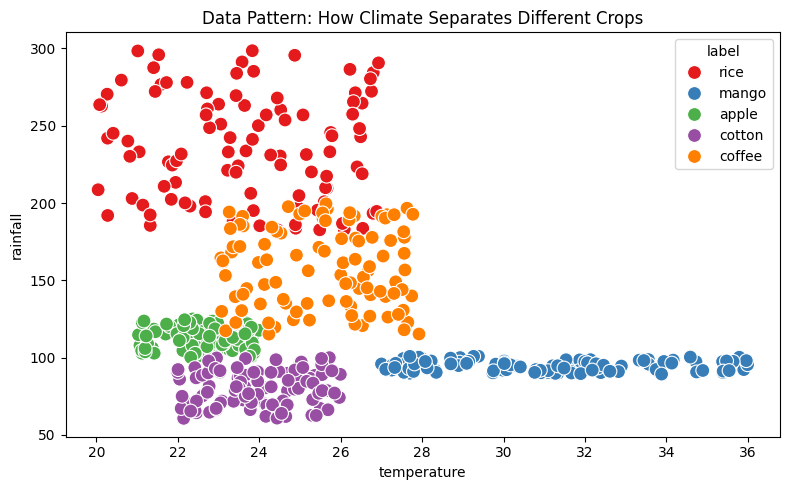

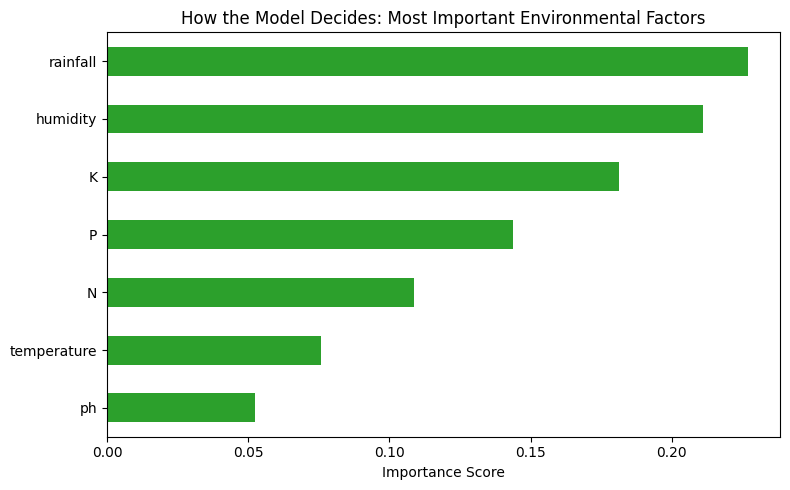

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# 1. FETCH DATA DIRECTLY
url = "https://raw.githubusercontent.com/delosreyesjohnpaul/Crop-Recommendation-System/main/Crop_recommendation.csv"
df = pd.read_csv(url)

# 2. GRAPH 1: THE PROBLEM (Filtered to 5 crops so it's easy to read)
# We plot temperature vs rainfall to show how the model sees patterns
sample_crops = df[df['label'].isin(['mango', 'apple', 'rice', 'cotton', 'coffee'])]
plt.figure(figsize=(8, 5))
sns.scatterplot(data=sample_crops, x='temperature', y='rainfall', hue='label', s=100, palette='Set1')
plt.title("Data Pattern: How Climate Separates Different Crops")
plt.tight_layout()
plt.savefig("1_climate_pattern.png")

# 3. NORMALIZATION (Fulfilling the rubric requirement)
X = df.drop('label', axis=1)
y = df['label']
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X) # Standardizes the data scale

# 4. BUILD THE ENSEMBLE MODEL
# n_estimators=100 creates the 100 decision trees for Bagging
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Print the final accuracy
y_pred = model.predict(X_test)
print(f"Ensemble Model Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")

# 5. GRAPH 2: HOW THE MODEL WORKS (Feature Importance)
plt.figure(figsize=(8, 5))
importances = pd.Series(model.feature_importances_, index=X.columns)
importances.sort_values().plot(kind='barh', color='#2ca02c')
plt.title("How the Model Decides: Most Important Environmental Factors")
plt.xlabel("Importance Score")
plt.tight_layout()
plt.savefig("2_model_logic.png")